# A Sample Notebook in a Sample REMARK

This notebook shows the kind of content a REMARK's notebook holds. A notebook should not be
only code: use markdown cells like this one to explain the model and what the code does.

`reproduce.sh` executes this notebook. It saves the two figures below in `figures/`, where the
LaTeX document `REMARK-starter-example.tex` includes them.

## The model

The consumer is HARK's `KinkyPrefConsumerType`. Each period they choose consumption $c$ out of
market resources $m$ (both normalized by permanent income), facing shocks to their income and
two further features:

- **Preference shocks:** a shock $\eta$ to the utility of consumption, $u(c, \eta)$, so that
  the consumer wants to spend more in some periods than in others.
- **A kinked interest rate:** the consumer pays more interest when borrowing,
  $\mathsf{R}_{boro}$, than they earn when saving, $\mathsf{R}_{save}$.

Solving the model gives the consumption function $c(m, \eta)$.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from HARK.ConsumptionSaving.ConsPrefShockModel import KinkyPrefConsumerType

from custom_code import plot_distribution

# The notebook runs in its own folder; figures go in the repository's figures/ folder.
figures = Path("../../figures")

## Solving the model

The consumer below has HARK's default parameters for this type, and an infinite horizon.

In [2]:
agent = KinkyPrefConsumerType()
agent.cycles = 0  # infinite horizon
agent.solve()

print(f"Interest factor when borrowing: {agent.Rboro}, when saving: {agent.Rsave}")
print(f"Relative risk aversion: {agent.CRRA}, discount factor: {agent.DiscFac}")

Interest factor when borrowing: 1.2, when saving: 1.02
Relative risk aversion: 2.0, discount factor: 0.96


## The consumption function

One line for each value of the preference shock $\eta$. Each line has two kinks, with a
short straight stretch between them where the consumer neither borrows nor saves and
consumes all of $m$: borrowing would cost $\mathsf{R}_{boro}$, while saving would earn only
$\mathsf{R}_{save}$.

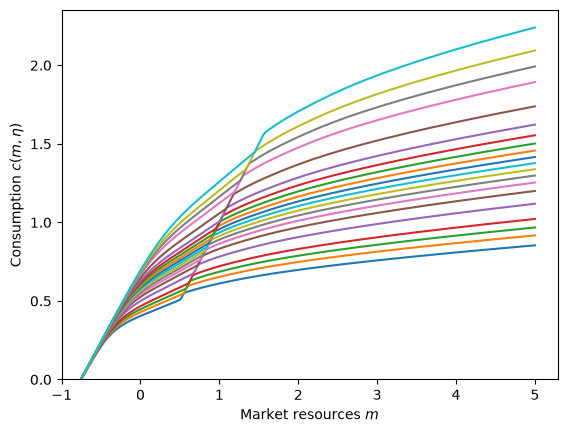

In [3]:
solution = agent.solution[0]
m = np.linspace(solution.mNrmMin, 5, 200)

fig, ax = plt.subplots()
for eta in agent.PrefShkDstn[0].atoms[0]:
    ax.plot(m, solution.cFunc(m, eta * np.ones_like(m)))
ax.set_xlim(-1.0, None)
ax.set_ylim(0.0, None)
ax.set_xlabel("Market resources $m$")
ax.set_ylabel(r"Consumption $c(m, \eta)$")
# Without a creation date, the same figure gives the same file on every run.
fig.savefig(figures / "cFunc.pdf", metadata={"CreationDate": None})
plt.show()

## Code kept in a module

Longer code is easier to maintain in a Python file next to the notebook: `custom_code.py`
holds the function below.

The function draws random numbers, so it takes a seed. With the same seed, every run draws
the same numbers and makes the same figure. A REMARK whose results depend on random draws
should always fix the seed.

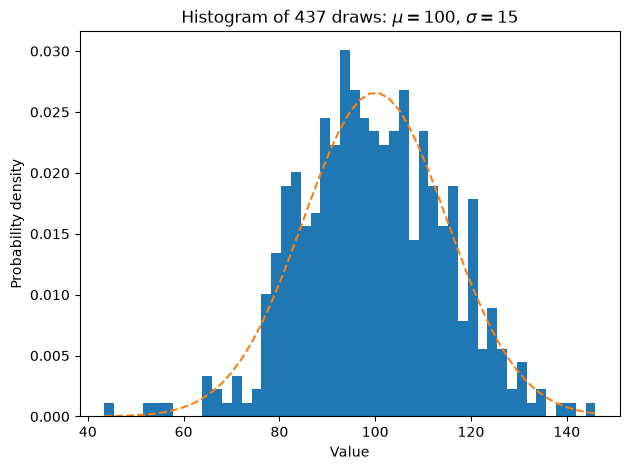

In [4]:
plot_distribution(mu=100, sigma=15, path=figures / "dist.pdf", seed=0)